In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import re
import warnings

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('social_media_engagement_5000.csv')

In [4]:
print(df.dtypes)

df['likes'] = pd.to_numeric(df['likes'], errors='coerce')
df['comments'] = pd.to_numeric(df['comments'], errors='coerce')
df['shares'] = pd.to_numeric(df['shares'], errors='coerce')

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [6]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

print(df['posted_at'].dtype)

datetime64[ns]


In [7]:
likes = np.array(df['likes'].dropna())

print("Likes Array:", likes)
print("Sum:", np.sum(likes))
print("Mean:", np.mean(likes))
print("Maximum:", np.max(likes))
print("Minimum:", np.min(likes))
print("Standard Deviation:", np.std(likes))

Likes Array: [ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Sum: 49019162.0
Mean: 10107.043711340206
Maximum: 19998.0
Minimum: 10.0
Standard Deviation: 5789.222332204696


In [8]:
df_fill = df.copy()

df_fill.fillna(0, inplace=True)

print(df_fill.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [9]:
df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

categorical_cols = df_clean.select_dtypes(include='object').columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print(df_clean.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [10]:
df_ffill = df.copy()

df_ffill = df_ffill.ffill()

df_bfill = df.copy()

df_bfill = df_bfill.bfill()

print("Forward Fill:")
print(df_ffill.isnull().sum())

print("Backward Fill:")
print(df_bfill.isnull().sum())

Forward Fill:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64
Backward Fill:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [11]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

df['likes'] = pd.to_numeric(df['likes'], errors='coerce')

df['comments'] = pd.to_numeric(df['comments'], errors='coerce')

df['shares'] = pd.to_numeric(df['shares'], errors='coerce')

print(df.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [12]:
df['gender'] = df['gender'].str.strip().str.lower()

df['gender'] = df['gender'].replace({
    'm': 'male',
    'f': 'female'
})

print(df['gender'].value_counts())

gender
male      1699
other     1581
female    1570
Name: count, dtype: int64


In [13]:
cols = ['likes', 'comments', 'shares']

for col in cols:
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

print(df[cols].describe())

              likes     comments     shares
count   5000.000000  5000.000000  5000.0000
mean   10106.997400  1502.039800  1002.9106
std     5702.293017   856.393312   570.8552
min       10.000000     0.000000     0.0000
25%     5235.000000   792.000000   511.0000
50%    10105.500000  1497.000000  1012.0000
75%    14959.000000  2235.250000  1483.0000
max    19998.000000  2999.000000  1999.0000


In [14]:
df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(re.findall(r'#\w+', str(x)))
)

print(df[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


In [15]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()

print(df['sentiment'].value_counts())

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64


In [16]:
print(df.head())
print(df.tail())

print("Shape:", df.shape)

print("Columns:", df.columns.tolist())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  female      UK   109864      text          food   4862.0   
3    64886  51.0   other  France   848877      text       fitness   5350.0   
4    16265  34.0   other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [17]:
df.info()

print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [18]:
print(df.describe())

            user_id          age        post_id         likes     comments  \
count   5000.000000  4850.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.454021  548042.909000  10106.997400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.912381  260646.957267   5702.293017   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000     4034.5

In [19]:
print(df['post_type'].value_counts())

print("Unique values:", df['post_type'].unique())

print("Number of unique values:", df['post_type'].nunique())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
Unique values: ['image' 'reel' 'text' 'video']
Number of unique values: 4


In [20]:
correlation = df.select_dtypes(include=np.number).corr()

print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006789  0.020051  0.025811 -0.033395  0.013763   
age              -0.006789  1.000000 -0.013353 -0.036767 -0.007369  0.014120   
post_id           0.020051 -0.013353  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036767  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007369 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.014120  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005677  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013513 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.025416 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008044  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007336  0.007344 -0.002190 -0.015230  0.013379   

                  watch_time_sec  impre

In [21]:
print(df.groupby('post_type')['likes'].mean())

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [22]:
print(df.groupby('country')['impression_count'].mean())

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64


In [23]:
df1 = df.iloc[:2500]

df2 = df.iloc[2500:]

combined_df = pd.concat([df1, df2], ignore_index=True)

print(combined_df.shape)

(5000, 20)


In [24]:
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares']
)

df['log_likes'] = np.log1p(df['likes'])

df['log_comments'] = np.log1p(df['comments'])

df['log_shares'] = np.log1p(df['shares'])

df['hashtag_count'] = df['hashtags'].apply(
    lambda x: len(re.findall(r'#\w+', str(x)))
)

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,...,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,...,False,mobile,negative,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,...,False,tablet,positive,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,...,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,...,False,mobile,negative,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888


In [25]:
print("Post Type Summary")

print(df.groupby('post_type')['engagement_score'].mean())

print("\nCountry Summary")

print(df.groupby('country')['engagement_score'].mean())

print("\nSentiment Summary")

print(df.groupby('sentiment')['engagement_score'].mean())

Post Type Summary
post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64

Country Summary
country
Australia    12809.621704
Brazil       12385.983135
Canada       12605.894737
France       12903.384073
Germany      12635.664286
India        12492.701869
Japan        12578.648305
UAE          12757.777336
UK           12384.374239
USA          12575.461078
Name: engagement_score, dtype: float64

Sentiment Summary
sentiment
negative    12731.498958
neutral     12448.163720
positive    12641.209056
Name: engagement_score, dtype: float64


In [26]:
cols = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

In [27]:
print(df[cols].mean())

likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64


In [28]:
print(df[cols].median())

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64


In [29]:
print(df[cols].mode())

        likes  comments  shares  watch_time_sec  engagement_rate  \
0     10105.5    1497.0  1012.0           916.0         0.006363   
1         NaN       NaN     NaN          2145.0         0.007420   
2         NaN       NaN     NaN          4360.0         0.012676   
3         NaN       NaN     NaN          7003.0         0.012692   
4         NaN       NaN     NaN          7688.0         0.015005   
...       ...       ...     ...             ...              ...   
4995      NaN       NaN     NaN             NaN        87.266094   
4996      NaN       NaN     NaN             NaN        92.828829   
4997      NaN       NaN     NaN             NaN       105.752212   
4998      NaN       NaN     NaN             NaN       121.931973   
4999      NaN       NaN     NaN             NaN       191.504348   

      follower_count  
0           497502.0  
1                NaN  
2                NaN  
3                NaN  
4                NaN  
...              ...  
4995             NaN  

In [30]:
print(df[cols].std())

likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64


In [31]:
print(df[cols].var())

likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


In [32]:
print(df[cols].quantile([0.25, 0.50, 0.75]))

        likes  comments  shares  watch_time_sec  engagement_rate  \
0.25   5235.0    792.00   511.0         2017.75         0.145781   
0.50  10105.5   1497.00  1012.0         4034.50         0.253896   
0.75  14959.0   2235.25  1483.0         6020.25         0.504794   

      follower_count  
0.25       194480.00  
0.50       388982.00  
0.75       589744.25  


In [33]:
print("Skewness:")

print(df[cols].skew())

print("Kurtosis:")

print(df[cols].kurtosis())

Skewness:
likes              -0.006894
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64
Kurtosis:
likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64


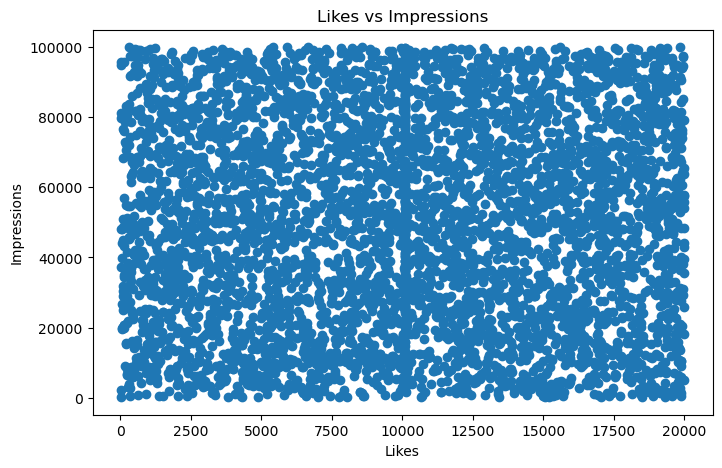

In [34]:
plt.figure(figsize=(8,5))

plt.scatter(df['likes'], df['impression_count'])

plt.xlabel('Likes')
plt.ylabel('Impressions')

plt.title('Likes vs Impressions')

plt.show()

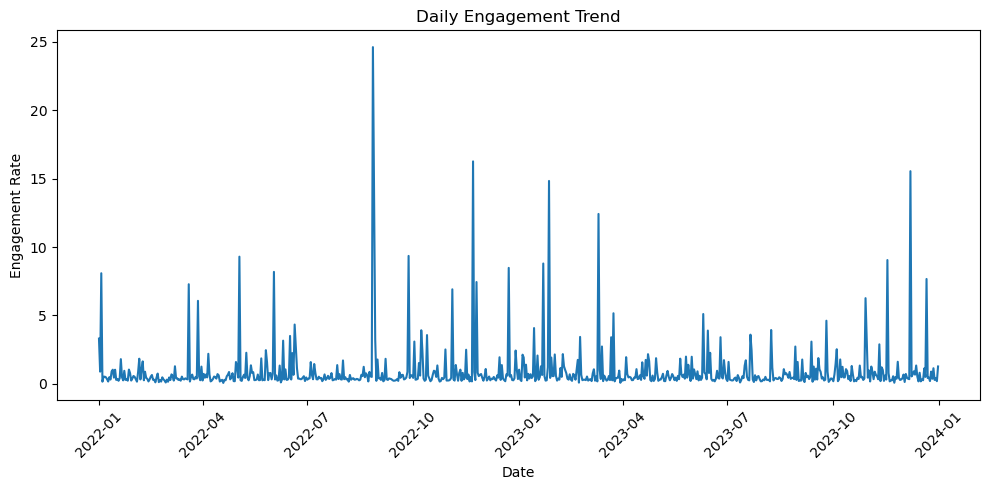

In [35]:
daily = df.groupby('posted_at')['engagement_rate'].mean()

plt.figure(figsize=(10,5))

plt.plot(daily.index, daily.values)

plt.xlabel('Date')
plt.ylabel('Engagement Rate')

plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

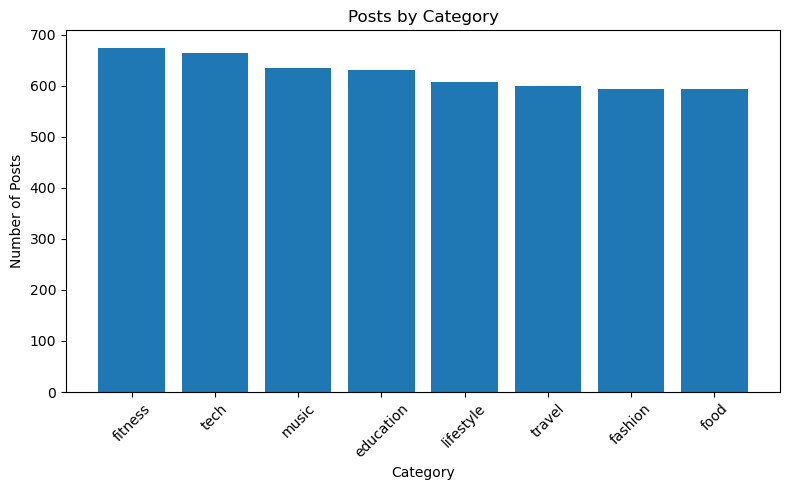

In [36]:
category = df['post_category'].value_counts()

plt.figure(figsize=(8,5))

plt.bar(category.index, category.values)

plt.xlabel('Category')
plt.ylabel('Number of Posts')

plt.title('Posts by Category')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

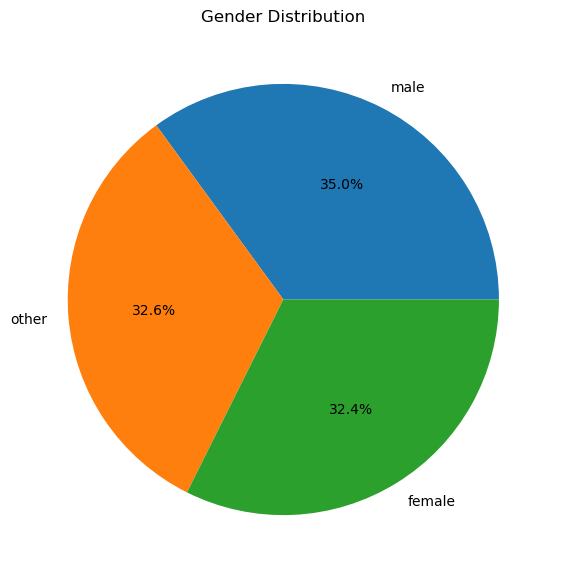

In [37]:
gender = df['gender'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender.values,
    labels=gender.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

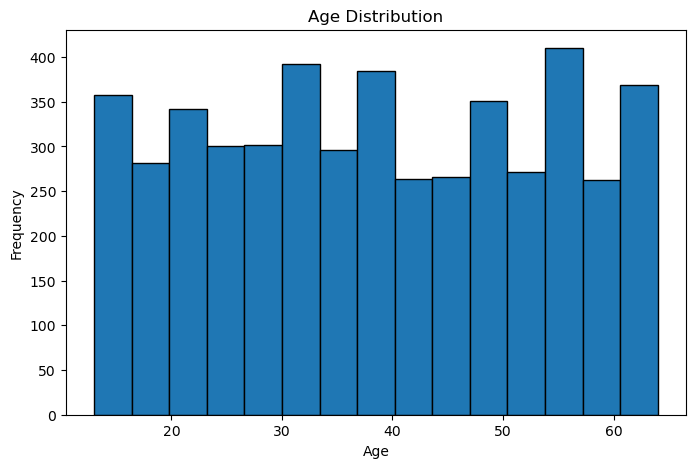

In [38]:
plt.figure(figsize=(8,5))

plt.hist(df['age'].dropna(), bins=15, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Frequency')

plt.title('Age Distribution')

plt.show()

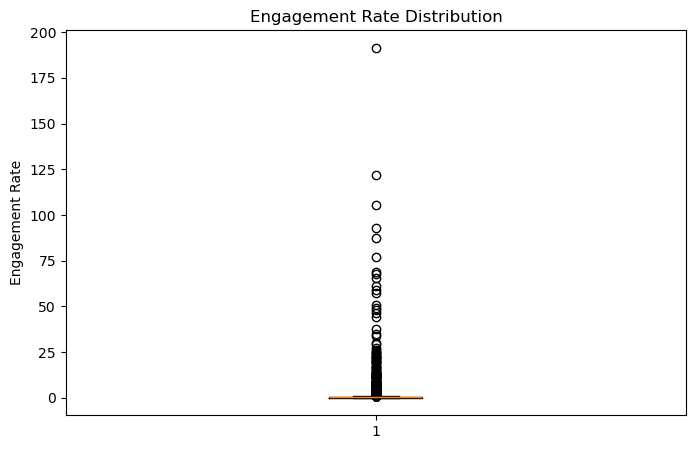

In [39]:
plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'].dropna())

plt.ylabel('Engagement Rate')

plt.title('Engagement Rate Distribution')

plt.show()

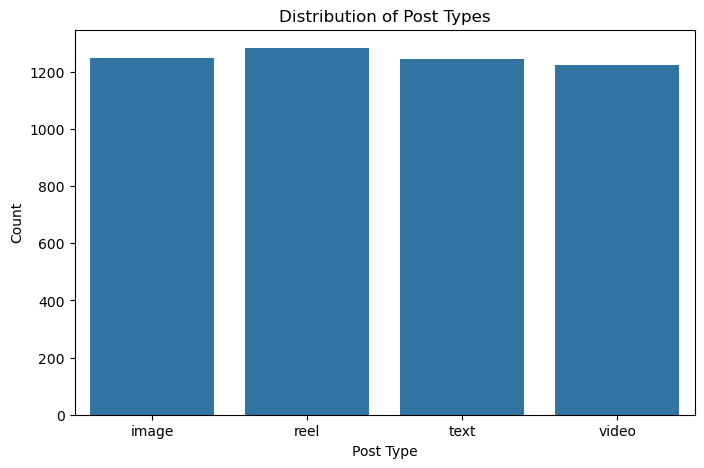

In [40]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='post_type')

plt.xlabel('Post Type')
plt.ylabel('Count')

plt.title('Distribution of Post Types')

plt.show()

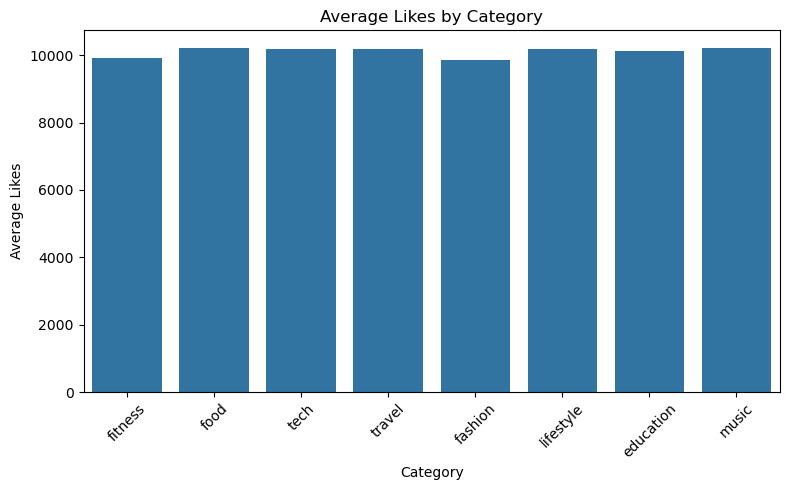

In [41]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.xlabel('Category')
plt.ylabel('Average Likes')

plt.title('Average Likes by Category')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

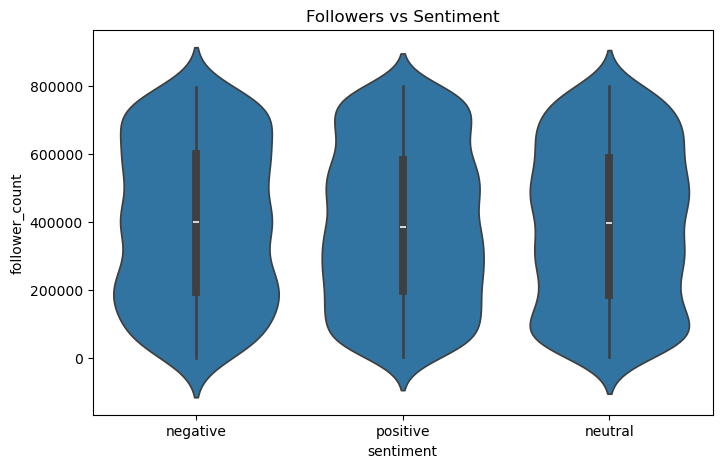

In [42]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Followers vs Sentiment')

plt.show()

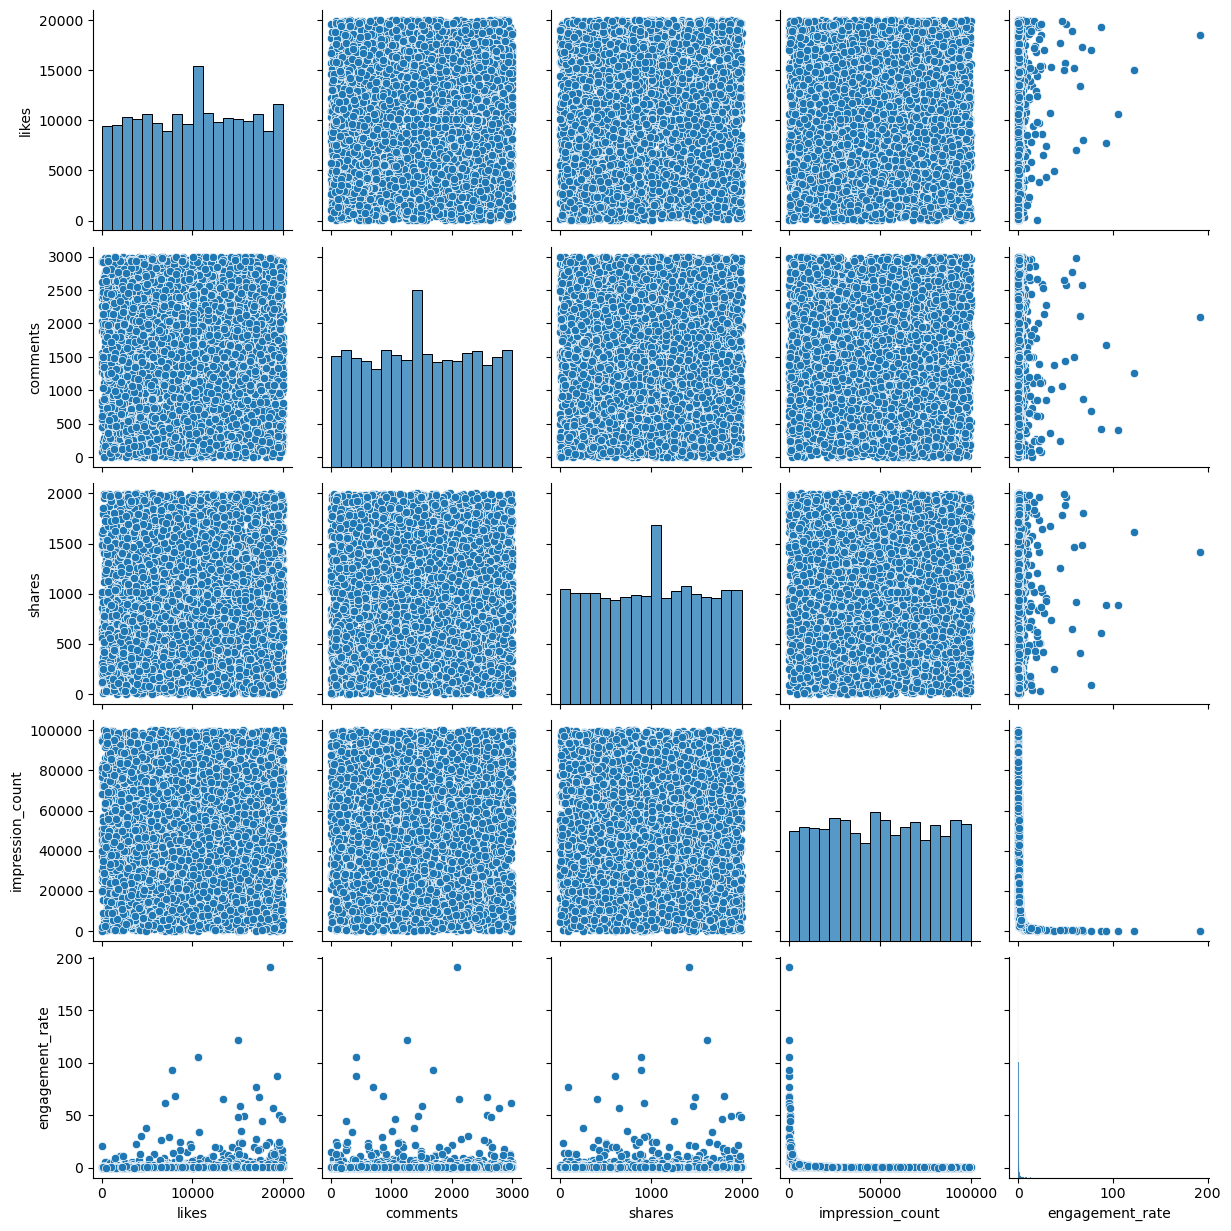

In [43]:
sns.pairplot(
    df[
        ['likes', 'comments', 'shares',
         'impression_count', 'engagement_rate']
    ].dropna()
)

plt.show()

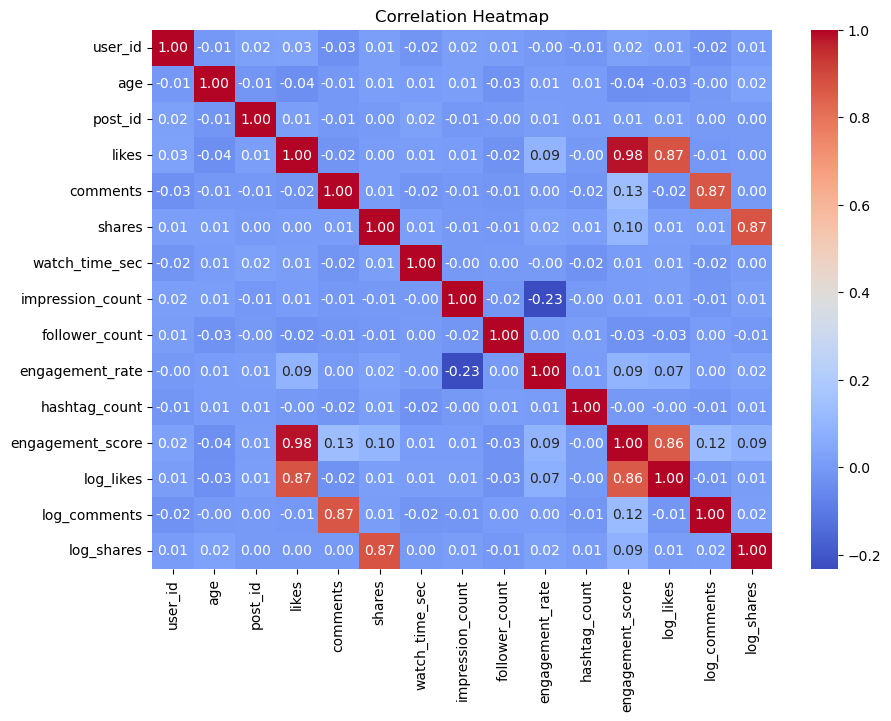

In [44]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

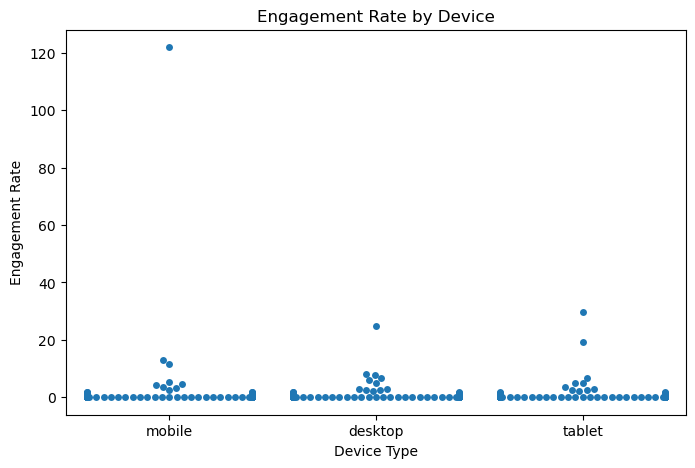

In [45]:
sample = df.sample(500, random_state=42)

plt.figure(figsize=(8,5))

sns.swarmplot(
    data=sample,
    x='device_type',
    y='engagement_rate'
)

plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.title('Engagement Rate by Device')

plt.show()

In [46]:
daily = df.groupby(
    'posted_at',
    as_index=False
)['engagement_rate'].mean()

fig = px.line(
    daily,
    x='posted_at',
    y='engagement_rate',
    title='Daily Engagement Trend'
)

fig.show()

In [47]:
post = df.groupby(
    'post_type',
    as_index=False
)['likes'].mean()

fig = px.bar(
    post,
    x='post_type',
    y='likes',
    title='Average Likes by Post Type'
)

fig.show()

In [48]:
fig = px.scatter(
    df,
    x='likes',
    y='impression_count',
    size='comments',
    color='post_type',
    title='Likes vs Impressions'
)

fig.show()

In [49]:
result = df.groupby('post_type')['engagement_score'].mean()

print(result.sort_values(ascending=False))

print("Highest Engagement:",
      result.idxmax())

post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement_score, dtype: float64
Highest Engagement: video


In [50]:
result = df.groupby('post_category')['engagement_score'].mean()

print(result.sort_values(ascending=False))

print("Best Category:", result.idxmax())

post_category
music        12788.549606
food         12739.200675
tech         12686.490226
travel       12650.559167
lifestyle    12639.539539
education    12578.270206
fitness      12457.791852
fashion      12356.420875
Name: engagement_score, dtype: float64
Best Category: music


In [51]:
result = df.groupby('country')['engagement_rate'].mean()

print(result.sort_values(ascending=False))

print("Top Country:", result.idxmax())

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64
Top Country: Brazil


In [52]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=['Below 18', '18-25', '26-35',
            '36-45', '46-60', 'Above 60']
)

result = df.groupby(
    'age_group',
    observed=False
)['engagement_rate'].mean()

print(result)

age_group
Below 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.858642
46-60       1.152669
Above 60    0.801381
Name: engagement_rate, dtype: float64


In [53]:
result = df.groupby('is_verified').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

print(result)

                    likes     comments       shares  engagement_rate
is_verified                                                         
False        10137.201129  1505.511401  1001.599292         0.954744
True          9824.533126  1469.573499  1015.173913         1.054250


In [54]:
print(df['posted_at'].head())

print(df['posted_at'].dtype)

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]
datetime64[ns]


In [55]:
result = df.groupby('device_type')['watch_time_sec'].mean()

print(result.sort_values(ascending=False))

print("Best Device:", result.idxmax())

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64
Best Device: mobile


In [56]:
result = df.groupby('sentiment')['engagement_rate'].mean()

print(result.sort_values(ascending=False))

print("Best Sentiment:", result.idxmax())

sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64
Best Sentiment: negative


In [57]:
result = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

summary = result.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

print(summary)

                  likes     comments       shares  engagement_rate
sentiment                                                         
negative   10208.096875  1516.094792  1007.307292         1.038486
neutral     9923.194499  1528.404060   996.565160         0.991170
